<a href="https://colab.research.google.com/github/rxphaelbihag/DS171-Intro-to-Supervised-Machine-Learning/blob/main/Laboratory_Exercise_8_Gradient_Boosted_Decision_Trees_on_Drug_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratory Exercise 8: Gradient Boosted Decision Trees on Drug Dataset

In [1]:
# Importing the libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
import sklearn.tree as tree

## Instructions:

*   Read and follow the given instructions.
*   A step-by-step process is given in each cell. Implement the required tasks.
*  Design, train, and evaluate a **Gradient Boosted Decision Trees (GBDT)** ensemble model for drug response multiclass classification.
*   For the synthesis questions, write your answers in the next cell. Your answers should be only 2-3 sentences.



Fetch and load the dataset

In [2]:
# Fetch data from IBM Object Storage repository
path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/drug200.csv'
my_data = pd.read_csv(path)
my_data.head(20)

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY
5,22,F,NORMAL,HIGH,8.607,drugX
6,49,F,NORMAL,HIGH,16.275,drugY
7,41,M,LOW,HIGH,11.037,drugC
8,60,M,NORMAL,HIGH,15.171,drugY
9,43,M,LOW,NORMAL,19.368,drugY


Preprocessing & Feature Encoding

In [3]:
# Separate features matrix X and response vector y
X = my_data[['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']].values
y = my_data["Drug"].values

# Label encode categorical features ('Sex', 'BP', 'Cholesterol')
from sklearn import preprocessing

le_sex = preprocessing.LabelEncoder()
X[:,1] = le_sex.fit_transform(X[:,1])

le_BP = preprocessing.LabelEncoder()
X[:,2] = le_BP.fit_transform(X[:,2])

le_Chol = preprocessing.LabelEncoder()
X[:,3] = le_Chol.fit_transform(X[:,3])

print("Sample preprocessed features (X):")
print(X[:5])

Sample preprocessed features (X):
[[23 0 0 0 25.355]
 [47 1 1 0 13.093]
 [47 1 1 0 10.114]
 [28 0 2 0 7.798]
 [61 0 1 0 18.043]]


Splitting the Dataset into Training Set and Test Set

In [4]:
from sklearn.model_selection import train_test_split

# Split data into 70% training set and 30% testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=3)

Building and Fitting the Gradient Boosted Decision Trees

In [5]:
# Instantiate and train the Gradient Boosting Ensemble
gbdt_classifier = GradientBoostingClassifier(n_estimators=100,
                                             learning_rate=0.1,
                                             max_depth=3,
                                             random_state=3)

gbdt_classifier.fit(X_train, y_train)

GradientBoostingClassifier(random_state=3)

Predicting Test Set Results and Output Probabilities

In [6]:
# Predicting Test set results
y_pred = gbdt_classifier.predict(X_test)

# Predict probability distribution across classes
probs_y = gbdt_classifier.predict_proba(X_test[:5])
probs_df = pd.DataFrame(probs_y, columns=gbdt_classifier.classes_)
probs_df['Predicted'] = y_pred[:5]
probs_df['True Label'] = y_test[:5]

print("Sample Predictions and Class Probabilities:")
probs_df.round(3)

Sample Predictions and Class Probabilities:


,drugA,drugB,drugC,drugX,drugY,Predicted,True Label
0,0.0,0.0,0.0,0.0,1.0,drugY,drugY
1,0.0,0.0,0.0,1.0,0.0,drugX,drugX
2,0.0,0.0,0.0,1.0,0.0,drugX,drugX
3,0.0,0.0,0.0,1.0,0.0,drugX,drugX
4,0.0,0.0,0.0,1.0,0.0,drugX,drugX


/tmp/ipykernel_769/2336207752.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=gbdt_classifier.feature_importances_, y=feature_names, palette='viridis')


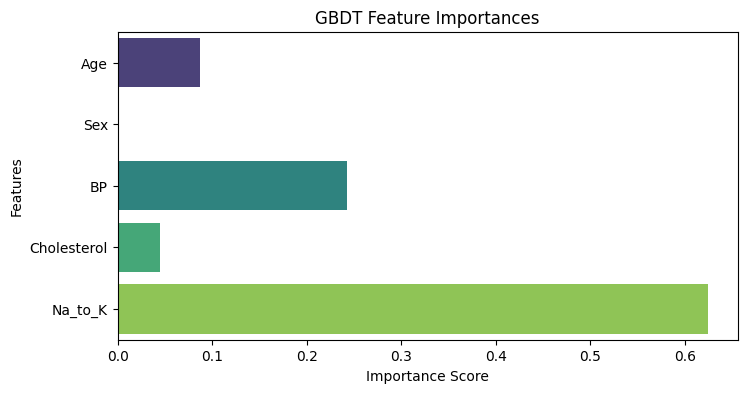

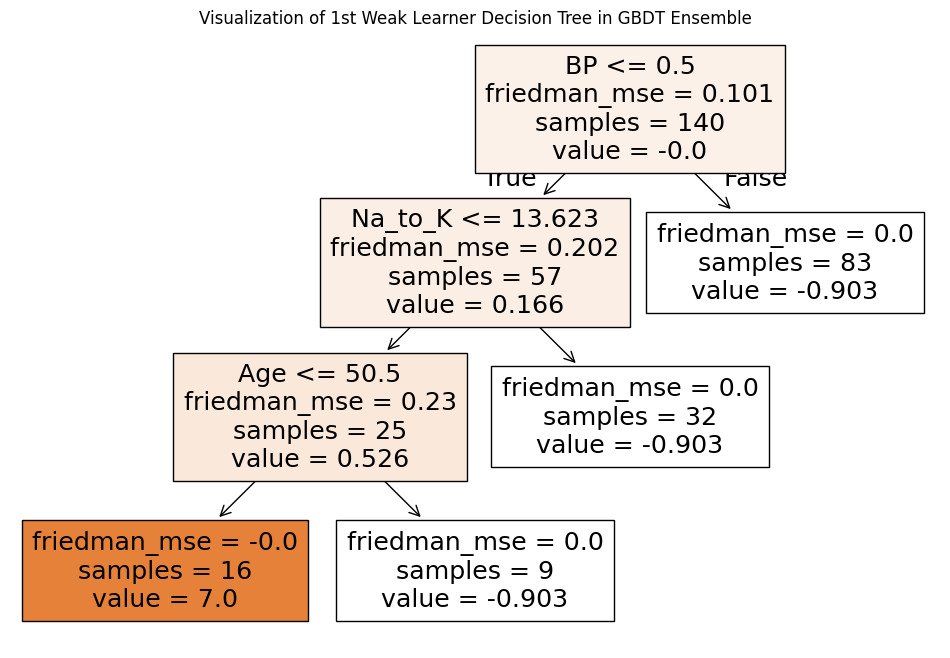

In [7]:
import seaborn as sns
feature_names = ['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']

# 1. Plot Feature Importances
plt.figure(figsize=(8, 4))
sns.barplot(x=gbdt_classifier.feature_importances_, y=feature_names, palette='viridis')
plt.title('GBDT Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# 2. Plot the 1st weak learner tree in the ensemble
plt.figure(figsize=(12, 8))
tree.plot_tree(gbdt_classifier.estimators_[0, 0],
               feature_names=feature_names,
               filled=True)
plt.title('Visualization of 1st Weak Learner Decision Tree in GBDT Ensemble')
plt.show()

## **Your** **Tasks**

1.   Create and plot the $5 \times 5$ Confusion Matrix.
2.   Calculate the overall test accuracy.
3.   Calculate the evaluation metrics (precision, recall, and F1-score) across all drugs.



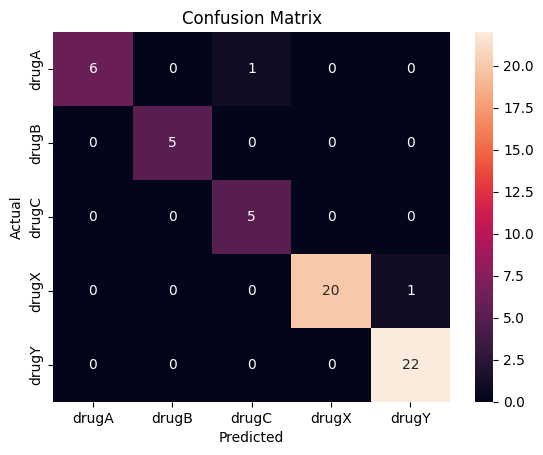

In [14]:
from sklearn import metrics

# Confusion Matrix
conf_matrix = metrics.confusion_matrix(y_test, y_pred)

# plot confusion matrix using seaborn's heatmap
classes = gbdt_classifier.classes_
sns.heatmap(conf_matrix, annot=True, xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [15]:
# Overall test accuracy
accuracy = metrics.accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 96.67%


In [16]:
# Classification Report
class_report = metrics.classification_report(y_test, y_pred)
print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

       drugA       1.00      0.86      0.92         7
       drugB       1.00      1.00      1.00         5
       drugC       0.83      1.00      0.91         5
       drugX       1.00      0.95      0.98        21
       drugY       0.96      1.00      0.98        22

    accuracy                           0.97        60
   macro avg       0.96      0.96      0.96        60
weighted avg       0.97      0.97      0.97        60



In [17]:
# === Modify test data split to 15% ===

# Separate features matrix X and response vector y
X = my_data[['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']].values
y = my_data["Drug"].values

# Label Encoding
le_sex = preprocessing.LabelEncoder()
X[:,1] = le_sex.fit_transform(X[:,1])
le_BP = preprocessing.LabelEncoder()
X[:,2] = le_BP.fit_transform(X[:,2])
le_Chol = preprocessing.LabelEncoder()
X[:,3] = le_Chol.fit_transform(X[:,3])

# Split data into 85% training set and 15% testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=3)

# Instantiate and train the Gradient Boosting Ensemble
gbdt_classifier_15 = GradientBoostingClassifier(n_estimators=100,
                                             learning_rate=0.1,
                                             max_depth=3,
                                             random_state=3)
gbdt_classifier_15.fit(X_train, y_train)

# Predicting Test set results
y_pred = gbdt_classifier.predict(X_test)

accuracy = metrics.accuracy_score(y_test, y_pred)
print(f"Accuracy at 15% test split: {accuracy*100:.2f}%")

Accuracy at 15% test split: 100.00%


In [19]:
# === Modify test data split to 25% ===

# Separate features matrix X and response vector y
X = my_data[['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']].values
y = my_data["Drug"].values

# Label Encoding
le_sex = preprocessing.LabelEncoder()
X[:,1] = le_sex.fit_transform(X[:,1])
le_BP = preprocessing.LabelEncoder()
X[:,2] = le_BP.fit_transform(X[:,2])
le_Chol = preprocessing.LabelEncoder()
X[:,3] = le_Chol.fit_transform(X[:,3])

# Split data into 85% training set and 15% testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=3)

# Instantiate and train the Gradient Boosting Ensemble
gbdt_classifier_15 = GradientBoostingClassifier(n_estimators=100,
                                             learning_rate=0.1,
                                             max_depth=3,
                                             random_state=3)
gbdt_classifier_15.fit(X_train, y_train)

# Predicting Test set results
y_pred = gbdt_classifier.predict(X_test)

accuracy = metrics.accuracy_score(y_test, y_pred)
print(f"Accuracy at 25% test split: {accuracy*100:.2f}%")

Accuracy at 25% test split: 98.00%


### **Analytical Questions**


*   Q1: How does Gradient Boosting sequential optimization reduce both variance and bias compared to a single standalone Decision Tree?
*   Q2: Examining your feature importance bar plot, which clinical patient feature plays the most dominant role in predicting drug response, and how does GBDT calculate relative feature importance across an ensemble of weak decision trees?
*   Q3: Modify the test data split to 15% and 25%. What did you observe about the accuracy of the model?



**Q1**
> Gradient Boosting sequential optimization reduces both variance and bias because its algorithm specifically addresses the errors of previous trees, thereby reducing bias. Additionally, it also restricts the depths of the trees, creating weak learners, and applies shrinkage of learning rate to the new trees, thereby reducing variance. This algorithm is particularly better than a single decision tree because its singularity necesitates for a greater depth to reduce bias but not too much to control variance growth.

**Q2:**
> From the feature importance bar plot, the feature Na_to_K appears to be dominating the prediction driver with approximately 64% of importance. The GBDT calculates this value by looking at the Freidman MSE and Samples of each split/node across all the weak decision trees it has made and averages it. In this way, it specifically looks at, on average, how each of the features contribute to the prediction of a result.

**Q3:**
> At different splits of the test data, the accuracy of the model changed dramatically, whereby at the 15% test data split, the model was able to achieve an accuracy of 100.00%, while the 25% test data split resulted to a 98.00% accuracy. In comparison with the baseline accuracy of 96.67% at 30% test data split, this shows the interplay of having more training data to learn from and having more testing data to accurately evaluate model accuracy. Ultimately, it boils down to the sufficient number of samples/data available to effectively train the model and enough testing samples to evaluate accuracy such that it mitigates illusions from class imbalance or increased score volatility due to smaller testing size.

##**Submission**:
Save all your code and analysis answers in a single Jupyter notebook. Make sure that your notebook has the student number, full name, and section commented in the first cell. Export the notebook with complete executed outputs and save it following the filename format “surname_section_labexe8.ipynb”.
- Submit your notebook to the LMS submission bin on or before the specified deadline.
- Late submission will be subject to a point deduction (10% per day, up to a 3-day maximum delay).
- Submissions that do not comply with the stated requirements and guidelines will be graded 0. Refer to the course syllabus for details on the source code evaluation rubric.